# Transaction Fraud Detection with Majority Voting

An educational extension of HKU COMP7409A Tutorial 1: compare five classical
classifiers and an equal-weight, three-out-of-five hard-voting ensemble.

**Workflow:** load and inspect data → hold out a test set → training-only EDA →
feature processing → five-fold cross-validation → final test comparison.

The label `RedFlag=1` denotes a flagged transaction, not independently confirmed fraud.
This is a course-data experiment, not a production fraud detection system.

**Colab:** run the setup cell, then Run all and upload `tranrecords.csv` when prompted.
**Local:** install `requirements.txt`, put the CSV in `data/`, and run the notebook or
`python fraud_detection.py`. See README for provenance and methodological changes.


In [1]:
# Install dependencies only inside Google Colab. Local setup uses requirements.txt.
import importlib.util
import subprocess
import sys

IN_COLAB = importlib.util.find_spec('google') is not None and importlib.util.find_spec('google.colab') is not None
if IN_COLAB:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           'numpy>=1.26,<3', 'pandas>=2.1,<3',
                           'matplotlib>=3.8,<4', 'scikit-learn>=1.4,<1.10'])


## 1. Imports and reproducibility
Fixed seeds make stochastic learners reproducible within a software environment.
Exact results can still vary across library versions. SGD uses `hinge` loss:
it is a linear SVM trained by SGD, not logistic regression.


In [2]:
import os
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value.to_string() if isinstance(value, pd.DataFrame) else value)
from pandas.plotting import scatter_matrix
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, ConfusionMatrixDisplay, make_scorer)
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier

SEED = 42
FEATURES = ['Amount', 'Fiscal Year', 'Status']
TARGET = 'RedFlag'
METRICS = ['Acc score', 'F1 score', 'Precision', 'Recall']
OUTPUT_DIR = Path('results')
OUTPUT_DIR.mkdir(exist_ok=True)
print('Versions:', {'numpy': np.__version__, 'pandas': pd.__version__, 'sklearn': sklearn.__version__})


Versions: {'numpy': '1.26.4', 'pandas': '2.2.3', 'sklearn': '1.8.0'}


## 2. Load data and inspect missing values
The lab represents missing values with `:`. Transactions with missing IDs are
dropped to retain the original lab's row-selection rule. IDs are not model inputs.
The target is never imputed. Other missing values are handled inside training pipelines.


In [3]:
data_path = Path(os.environ.get('LAB1_DATA_PATH', 'data/tranrecords.csv'))
if not data_path.exists() and Path('tranrecords.csv').exists():
    data_path = Path('tranrecords.csv')
if not data_path.exists() and IN_COLAB:
    from google.colab import files
    print('Upload the course file tranrecords.csv')
    uploaded = files.upload()
    if 'tranrecords.csv' not in uploaded:
        raise ValueError('Please upload a file named tranrecords.csv.')
    data_path = Path('tranrecords.csv')
if not data_path.exists():
    raise FileNotFoundError('Place tranrecords.csv in data/ or set LAB1_DATA_PATH to its location.')

raw = pd.read_csv(data_path, na_values=':')
required = ['Amount', 'TranNo', 'Status', 'Department', 'Fiscal Year', 'Month', TARGET]
missing_columns = set(required) - set(raw.columns)
if missing_columns:
    raise ValueError(f'Missing columns: {sorted(missing_columns)}')
print('Original rows:', len(raw))
display(raw.isna().sum().rename('Missing values').to_frame())

df = raw.dropna(subset=['TranNo', TARGET]).copy()
if not df[TARGET].isin([0, 1]).all():
    raise ValueError('RedFlag must contain only 0 and 1.')
df[TARGET] = df[TARGET].astype(int)
for col in ['Amount', 'Fiscal Year']:
    df[col] = pd.to_numeric(df[col], errors='raise')
    if not np.isfinite(df[col].dropna()).all():
        raise ValueError(f'{col} contains infinite values.')
if (df['Amount'].dropna() < 0).any():
    raise ValueError('This example assumes non-negative transaction amounts for log1p.')
unknown_status = set(df['Status'].dropna()) - {'Paid_Reconciled', 'Paid_UnReconciled'}
if unknown_status:
    raise ValueError(f'Unexpected status values: {unknown_status}')
print('Rows retained:', len(df), '| Rows removed:', len(raw) - len(df))


,Missing values
Amount,0
TranNo,44
Status,41
Department,14
Fiscal Year,55
Month,22
RedFlag,0


Original rows: 2500
Rows retained: 2456 | Rows removed: 44


## 3. Hold out 20% for the final test
Use a stratified split to retain class proportions. All exploratory plots below
use the training partition. No feature selection or hyperparameter tuning uses
test scores. A random split is an educational assumption; it does not establish
performance on future years or on new customers.


In [4]:
train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=SEED, stratify=df[TARGET]
)
assert set(train_df.index).isdisjoint(test_df.index)
X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]
print(f'Training rows: {len(train_df)} | Test rows: {len(test_df)}')
display(y_train.value_counts().sort_index().rename('Training count').to_frame())
print(f'Training positive proportion: {y_train.mean():.2%}')


,Training count
RedFlag,
0,1707
1,257


Training rows: 1964 | Test rows: 492
Training positive proportion: 13.09%


## 4. Training-set EDA and missing-value illustration
For these descriptive plots only, fill year with its training mean, month and
department with their training modes, and status with `Paid_UnReconciled`, matching
the lab's teaching choices. Assigning an unknown status to unreconciled is an
assumption, not evidence that a payment is unreconciled. Fractional mean years are
also a teaching simplification. Model pipelines separately learn their statistics
inside each training fold; this EDA copy is never passed to cross-validation.


,Amount,TranNo,Status,Department,Fiscal Year,Month,RedFlag
1432,2.747059,A952517,Paid_UnReconciled,Finance,2012.0,Aug,0
71,5.609452,E353375,Paid_Reconciled,Marketing,2018.0,Aug,0
1405,1.217521,C771452,Paid_Reconciled,Finance,2019.0,Sep,0
716,0.060022,C392847,Paid_Reconciled,Finance,2010.0,Apr,0
2316,11.158234,C859800,Paid_UnReconciled,Purchasing,2013.0,Oct,1
765,10.477649,C739029,Paid_UnReconciled,Finance,2019.0,Oct,0
1265,12.635193,C167887,Paid_Reconciled,Finance,2018.0,Feb,0
2226,3.423727,E470547,Paid_UnReconciled,Finance,2015.0,Jul,0
475,50.721982,C930937,Paid_UnReconciled,Finance,2010.0,Feb,0
635,0.094292,C085855,Paid_UnReconciled,Finance,2018.0,Aug,0


,Amount,TranNo,Status,Department,Fiscal Year,Month,RedFlag
1399,0.097204,C713842,Paid_Reconciled,Purchasing,2015.0,May,0
2224,3.754598,E345855,Paid_UnReconciled,Finance,2013.0,Feb,0
2446,68.506332,C386397,Paid_Reconciled,Production,2018.0,Apr,1
1759,1.125004,C301603,Paid_Reconciled,Marketing,2010.0,May,0
1439,2.590252,E948320,Paid_Reconciled,Finance,2018.0,Aug,0
1547,34.589900,C554985,Paid_UnReconciled,Production,2011.0,Sep,0
650,11.673038,A878424,Paid_Reconciled,Finance,2015.0,Sep,0
2294,1.150310,C276616,Paid_Reconciled,Marketing,2010.0,Feb,0
797,0.825976,C792805,Paid_Reconciled,Purchasing,2012.0,Apr,0
65,27.074830,C062919,Paid_Reconciled,R&D,2011.0,Apr,0


,Amount,Fiscal Year,RedFlag
count,1964.000000,1964.000000,1964.000000
mean,33.047863,2014.548622,0.130855
std,170.045257,2.909065,0.337328
min,0.001359,2010.000000,0.000000
25%,1.134144,2012.000000,0.000000
50%,4.413811,2014.548622,0.000000
75%,19.285523,2017.000000,0.000000
max,4060.364437,2019.000000,1.000000


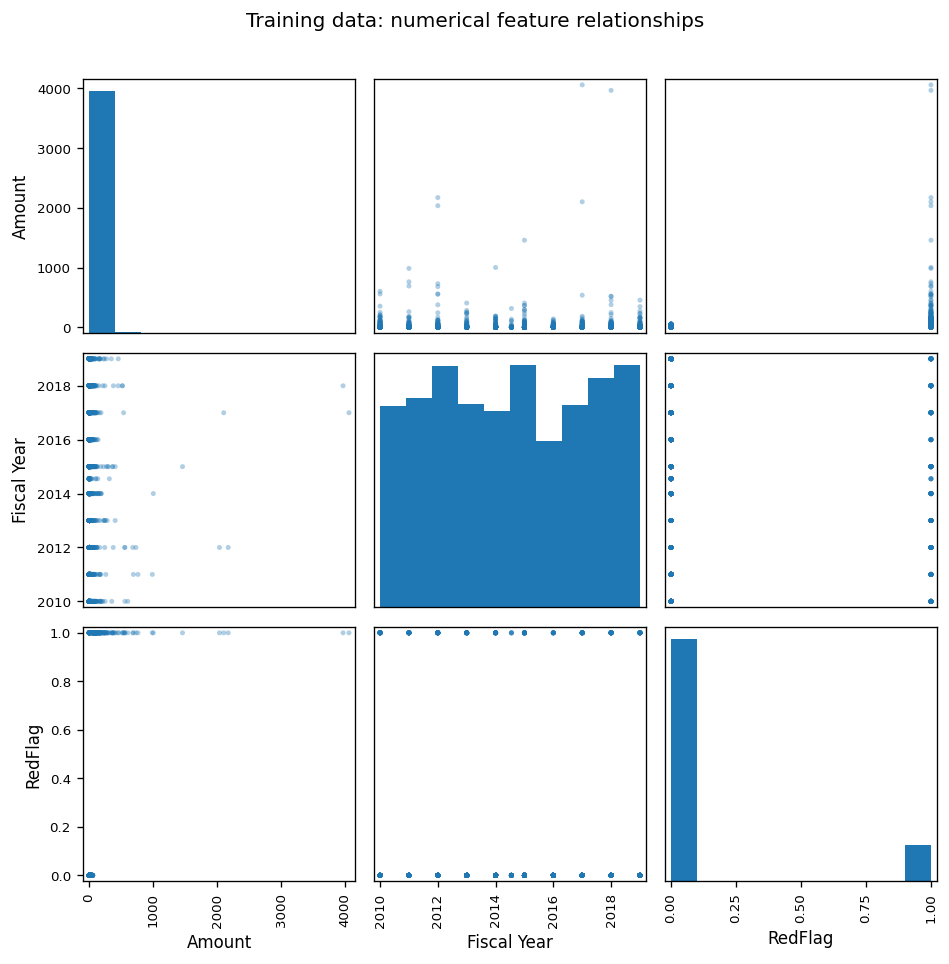

RedFlag,0,1
Status,,
Paid_Reconciled,1207,137
Paid_UnReconciled,500,120


RedFlag,0,1
Status,,
Paid_Reconciled,0.707088,0.533074
Paid_UnReconciled,0.292912,0.466926


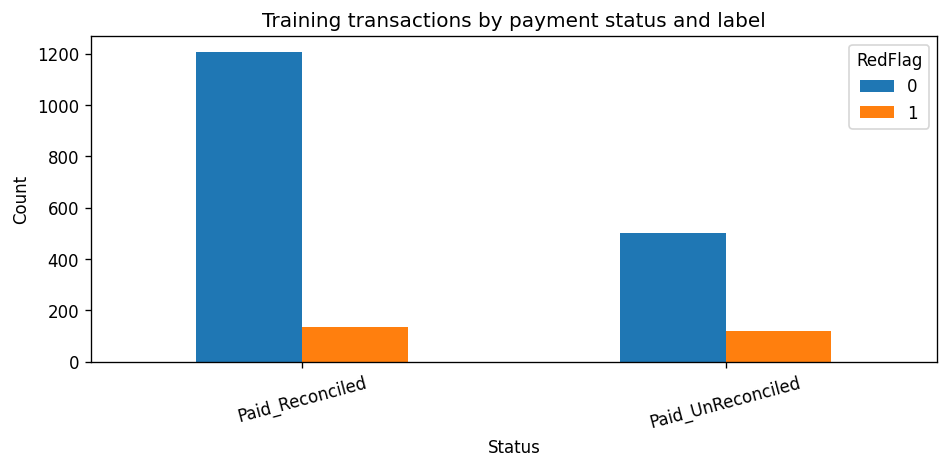

<class 'pandas.core.frame.DataFrame'>
Index: 1964 entries, 1432 to 65
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Amount       1964 non-null   float64
 1   TranNo       1964 non-null   object 
 2   Status       1964 non-null   object 
 3   Department   1964 non-null   object 
 4   Fiscal Year  1964 non-null   float64
 5   Month        1964 non-null   object 
 6   RedFlag      1964 non-null   int32  
dtypes: float64(2), int32(1), object(4)
memory usage: 115.1+ KB


In [5]:
eda = train_df.copy()
eda['Fiscal Year'] = eda['Fiscal Year'].fillna(eda['Fiscal Year'].mean())
eda['Status'] = eda['Status'].fillna('Paid_UnReconciled')
for col in ['Month', 'Department']:
    eda[col] = eda[col].fillna(eda[col].mode().iloc[0])
display(eda.head(10))
display(eda.tail(10))
eda.info()
display(eda.describe())

scatter_matrix(eda[['Amount', 'Fiscal Year', TARGET]], figsize=(8, 8), alpha=0.35)
plt.suptitle('Training data: numerical feature relationships', y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

status_counts = pd.crosstab(eda['Status'], eda[TARGET]).reindex(columns=[0, 1], fill_value=0)
display(status_counts)
display(pd.crosstab(eda['Status'], eda[TARGET], normalize='columns'))
status_counts.plot(kind='bar', figsize=(8, 4), rot=15)
plt.title('Training transactions by payment status and label')
plt.ylabel('Count')
plt.tight_layout()
plt.show()


## 5. Amount transformation and outlier inspection
Compare raw and log-transformed amounts. `log1p(x)` is `log(x + 1)` and preserves
ordering while compressing large values. Boxplot whiskers use the 1.5-IQR rule;
points beyond them are potential outliers. Keep them: unusual transactions may
be relevant to this task. Always derive log amounts from raw data to avoid repeated logs.


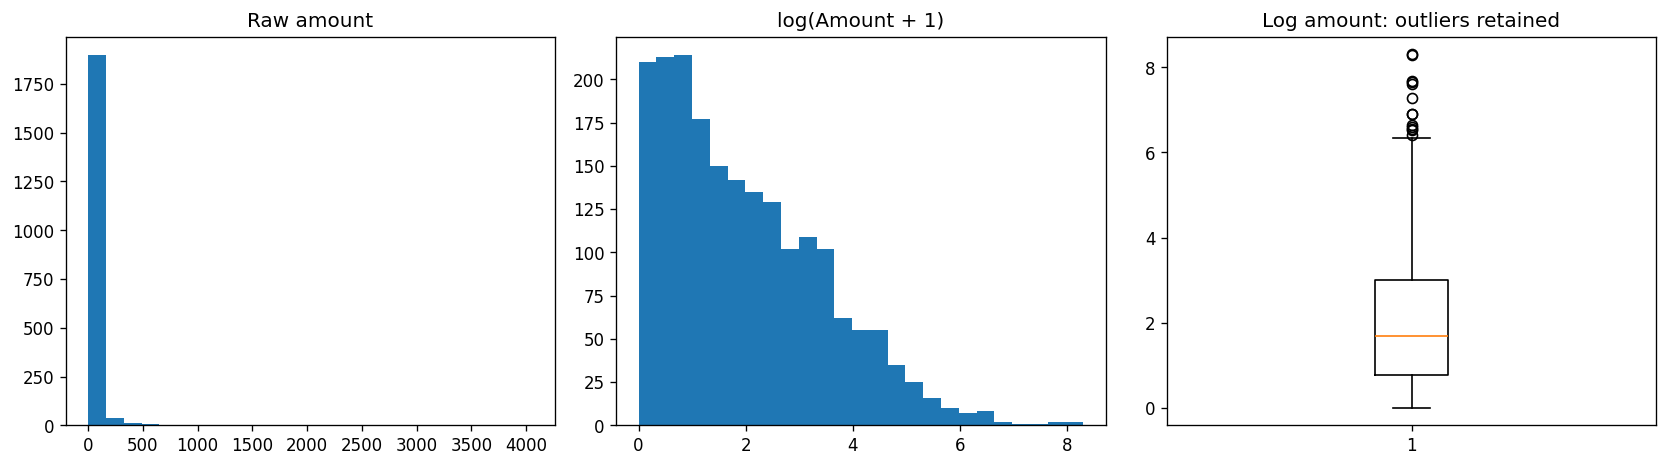

In [6]:
amount_log = np.log1p(eda['Amount'])
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(eda['Amount'].dropna(), bins=25)
axes[0].set_title('Raw amount')
axes[1].hist(amount_log.dropna(), bins=25)
axes[1].set_title('log(Amount + 1)')
axes[2].boxplot(amount_log.dropna())
axes[2].set_title('Log amount: outliers retained')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'amount_distributions.png', dpi=150)
plt.show()


## 6. Encoding and correlation (descriptive only)
Reproduce the lab's integer mappings and Pearson correlation heatmap. Department
codes are arbitrary, so their Pearson correlations should not be interpreted as
meaningful order effects. Month codes also ignore seasonality across December/January.
The three model inputs are fixed from the lab, not selected by test performance.


,Amount,Status,Department,Fiscal Year,Month,RedFlag
Amount,1.000,0.029,0.007,-0.014,0.008,0.614
Status,0.029,1.000,-0.020,0.003,0.017,0.126
Department,0.007,-0.020,1.000,-0.050,0.034,0.022
Fiscal Year,-0.014,0.003,-0.050,1.000,-0.016,-0.035
Month,0.008,0.017,0.034,-0.016,1.000,0.026
RedFlag,0.614,0.126,0.022,-0.035,0.026,1.000


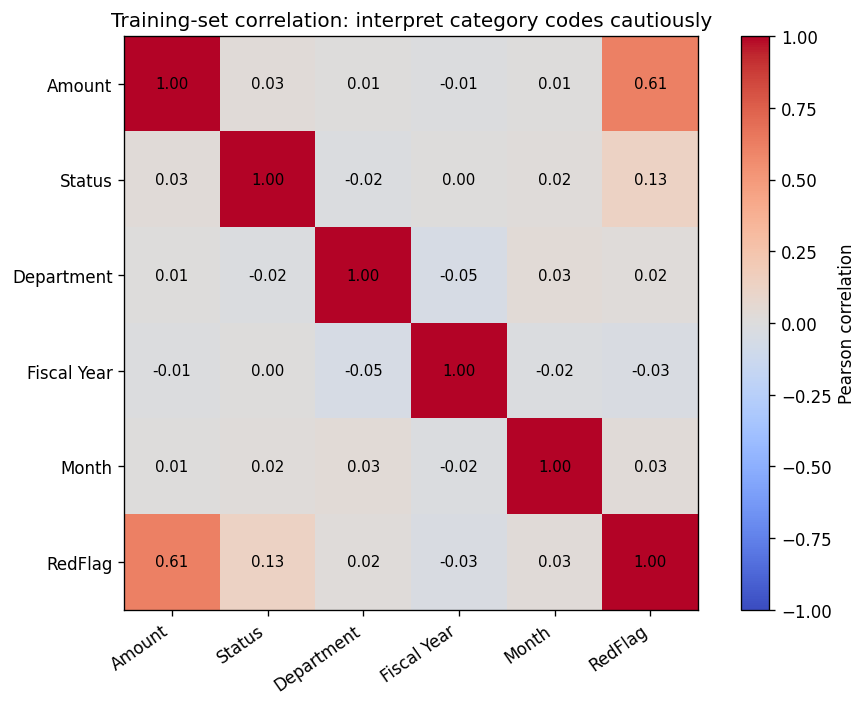

In [7]:
encoded = eda.copy()
encoded['Amount'] = amount_log
encoded['Month'] = encoded['Month'].map(dict(zip(
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'], range(1, 13))))
encoded['Status'] = encoded['Status'].map({'Paid_Reconciled': 0, 'Paid_UnReconciled': 1})
encoded['Department'] = encoded['Department'].map(
    {'Finance': 0, 'Marketing': 1, 'Production': 2, 'Purchasing': 3, 'R&D': 4})
encoded = encoded.drop(columns=['TranNo'])
cols = ['Amount', 'Status', 'Department', 'Fiscal Year', 'Month', TARGET]
cor_matrix = encoded[cols].corr()
display(cor_matrix.round(3))
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(cor_matrix, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(cols)), labels=cols, rotation=35, ha='right')
ax.set_yticks(range(len(cols)), labels=cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f'{cor_matrix.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9)
fig.colorbar(im, ax=ax, label='Pearson correlation')
ax.set_title('Training-set correlation: interpret category codes cautiously')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'correlation.png', dpi=150)
plt.show()


## 7. Preprocessing and five fixed classifiers
Each pipeline imputes missing values, applies log1p to amount, encodes the binary
payment status, and standardizes features. Pipelines fit only on their training
data, including inside cross-validation. Trees do not need standardization, but
use the same inputs here to keep the lab comparison simple.

Retain the lab's shallow-tree settings (DT depth 2; RF depth 3). Set random seeds
and specify 100 forest trees. Logistic regression uses L2 regularization; SGD uses
hinge loss and L2 regularization. These are fixed educational baselines, not tuned models.


In [8]:
def make_preprocessor():
    return ColumnTransformer([
        ('amount', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one'))
        ]), ['Amount']),
        ('year', SimpleImputer(strategy='mean'), ['Fiscal Year']),
        ('status', Pipeline([
            ('impute', SimpleImputer(strategy='constant', fill_value='Paid_UnReconciled')),
            ('encode', OrdinalEncoder(categories=[['Paid_Reconciled', 'Paid_UnReconciled']]))
        ]), ['Status'])
    ])

def make_pipeline(estimator, scale=True):
    return Pipeline([
        ('prepare', make_preprocessor()),
        ('scale', StandardScaler() if scale else 'passthrough'),
        ('model', clone(estimator))
    ])

estimators = {
    'GaussianNB': GaussianNB(),
    'LogisticReg': LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000, random_state=SEED),
    'DecisionTree': DecisionTreeClassifier(max_features=0.2, max_depth=2,
                                           min_samples_split=2, random_state=SEED),
    'RandomForest': RandomForestClassifier(n_estimators=100, max_depth=3, random_state=SEED),
    'SGDClassifier': SGDClassifier(loss='hinge', penalty='l2', alpha=0.0001,
                                   max_iter=1000, tol=0.001, random_state=SEED)
}
pipelines = {name: make_pipeline(model) for name, model in estimators.items()}
voting_model = VotingClassifier(estimators=[
    (name, clone(model)) for name, model in estimators.items()
], voting='hard')
ensemble_pipeline = make_pipeline(voting_model)


## 8. Five-fold validation on the training partition
Evaluate all five models and the voting ensemble on identical stratified folds.
Report accuracy, F1, precision and recall; positive class is RedFlag=1. Fold means
and standard deviations describe this split, not a formal confidence interval.
Preprocessing is re-fitted in each fold. No test data is used here and no automatic
hyperparameter search is performed.


,Learner,accuracy_mean,accuracy_std,f1_mean,f1_std,precision_mean,precision_std,recall_mean,recall_std,train_f1_mean
0,GaussianNB,0.9664,0.0101,0.8616,0.0403,0.9373,0.0497,0.7977,0.0398,0.8594
1,LogisticReg,0.9527,0.0085,0.7985,0.0339,0.9036,0.0482,0.7161,0.0340,0.7952
2,DecisionTree,0.9588,0.0172,0.8073,0.1001,1.0000,0.0000,0.6854,0.1285,0.8010
3,RandomForest,0.9756,0.0053,0.8966,0.0243,1.0000,0.0000,0.8133,0.0393,0.8993
4,SGDClassifier,0.9506,0.0169,0.8088,0.0506,0.8481,0.1256,0.7858,0.0654,0.7871
5,MajorityVote,0.9684,0.0103,0.8700,0.0408,0.9476,0.0571,0.8055,0.0451,0.8706


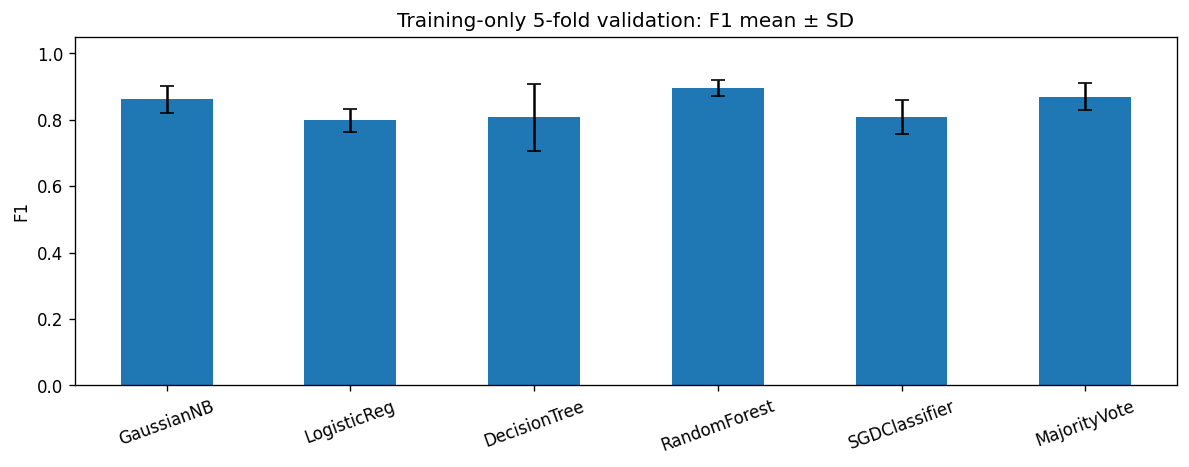

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    'accuracy': 'accuracy',
    'f1': make_scorer(f1_score, zero_division=0),
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0)
}
cv_rows = []
for name, pipeline in {**pipelines, 'MajorityVote': ensemble_pipeline}.items():
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring,
                            return_train_score=True, n_jobs=1, error_score='raise')
    row = {'Learner': name}
    for metric in scoring:
        row[f'{metric}_mean'] = scores[f'test_{metric}'].mean()
        row[f'{metric}_std'] = scores[f'test_{metric}'].std(ddof=1)
    row['train_f1_mean'] = scores['train_f1'].mean()
    cv_rows.append(row)
cv_results = pd.DataFrame(cv_rows)
display(cv_results.round(4))
cv_results.to_csv(OUTPUT_DIR / 'cross_validation_metrics.csv', index=False)

ax = cv_results.plot.bar(x='Learner', y='f1_mean', yerr='f1_std',
                         legend=False, capsize=4, figsize=(10, 4), rot=20)
ax.set(title='Training-only 5-fold validation: F1 mean ± SD', ylabel='F1', xlabel='')
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'cross_validation_f1.png', dpi=150)
plt.show()


### Scaling demonstration for SGD
Compare the same SGD settings with and without StandardScaler using training-only
cross-validation. Both versions still use log-transformed amount and identical imputation.
This illustration does not change the fixed models in the final comparison.


In [10]:
scaling_rows = []
for scaled in [False, True]:
    scores = cross_validate(make_pipeline(estimators['SGDClassifier'], scale=scaled),
                            X_train, y_train, cv=cv, scoring=scoring, error_score='raise')
    scaling_rows.append({'Standardized': scaled,
                         **{metric: scores[f'test_{metric}'].mean() for metric in scoring}})
display(pd.DataFrame(scaling_rows).round(4))


,Standardized,accuracy,f1,precision,recall
0,False,0.7211,0.0459,0.0260,0.2000
1,True,0.9506,0.8088,0.8481,0.7858


## 9. Final fit and test-set majority vote
Fit each model once on the full training partition. Each of the five models gets
one equal vote; at least three positive predictions produce an ensemble prediction
of 1. The random forest contributes one vote, regardless of its internal tree count.

Compare on the untouched 20% test partition. These results describe pre-specified
models; choosing or tuning models repeatedly from this table would reuse the test set.
The ensemble is not guaranteed to beat the best individual classifier.


In [11]:
fitted_models, predictions, timing_rows = {}, {}, []
for name, pipeline in pipelines.items():
    fitted = clone(pipeline)
    start = perf_counter()
    fitted.fit(X_train, y_train)
    fit_seconds = perf_counter() - start
    start = perf_counter()
    predictions[name] = fitted.predict(X_test)
    predict_seconds = perf_counter() - start
    fitted_models[name] = fitted
    timing_rows.append({'Learner': name, 'Train Time': fit_seconds, 'Pred Time': predict_seconds})

votes = pd.DataFrame(predictions, index=X_test.index)
start = perf_counter()
y_pred_vote = (votes.eq(1).sum(axis=1) >= 3).astype(int).to_numpy()
vote_seconds = perf_counter() - start
predictions['MajorityVote'] = y_pred_vote

def evaluate(name, pred):
    return {'Learner': name,
            'Acc score': accuracy_score(y_test, pred),
            'F1 score': f1_score(y_test, pred, zero_division=0),
            'Precision': precision_score(y_test, pred, zero_division=0),
            'Recall': recall_score(y_test, pred, zero_division=0)}

summary = pd.DataFrame([evaluate(name, pred) for name, pred in predictions.items()])
display(summary.round(4))
summary.to_csv(OUTPUT_DIR / 'test_metrics.csv', index=False)

# The ensemble reuses the five fits; its standalone serial cost includes all five.
timings = pd.DataFrame(timing_rows)
ensemble_timing = pd.DataFrame([{'Learner': 'MajorityVote',
    'Train Time': timings['Train Time'].sum(),
    'Pred Time': timings['Pred Time'].sum() + vote_seconds}])
timings = pd.concat([timings, ensemble_timing], ignore_index=True)
display(timings.round(6))
timings.to_csv(OUTPUT_DIR / 'timings_seconds.csv', index=False)

print(f'Always-normal accuracy baseline: {(y_test == 0).mean():.4f}')
print(classification_report(y_test, y_pred_vote, labels=[0, 1],
      target_names=['Normal', 'Red-flagged'], zero_division=0))

vote_details = votes.copy()
vote_details['Votes for 1'] = votes.eq(1).sum(axis=1)
vote_details['MajorityVote'] = y_pred_vote
vote_details['Actual'] = y_test
display(vote_details.head(10))
assert np.array_equal(y_pred_vote, (votes.to_numpy().sum(axis=1) >= 3).astype(int))
assert len(y_pred_vote) == len(y_test)
assert np.isin(y_pred_vote, [0, 1]).all()


,Learner,Acc score,F1 score,Precision,Recall
0,GaussianNB,0.9715,0.8906,0.9048,0.8769
1,LogisticReg,0.9533,0.8160,0.8500,0.7846
2,DecisionTree,0.9776,0.9076,1.0000,0.8308
3,RandomForest,0.9858,0.9431,1.0000,0.8923
4,SGDClassifier,0.9736,0.8960,0.9333,0.8615
5,MajorityVote,0.9756,0.9048,0.9344,0.8769


,Learner,Train Time,Pred Time
0,GaussianNB,0.008550,0.003941
1,LogisticReg,0.010508,0.005015
2,DecisionTree,0.008517,0.003699
3,RandomForest,0.117938,0.010071
4,SGDClassifier,0.016143,0.004718
5,MajorityVote,0.161656,0.027962


,GaussianNB,LogisticReg,DecisionTree,RandomForest,SGDClassifier,Votes for 1,MajorityVote,Actual
2268,0,0,0,0,0,0,0,0
1960,1,1,1,1,1,5,1,1
2310,0,0,0,0,0,0,0,0
1829,0,0,0,0,0,0,0,0
1572,0,0,0,0,0,0,0,0
289,0,0,0,0,0,0,0,0
1534,0,0,0,0,0,0,0,0
2340,0,0,0,0,0,0,0,0
2366,1,1,1,1,1,5,1,1
854,0,0,0,0,0,0,0,0


Always-normal accuracy baseline: 0.8679
              precision    recall  f1-score   support

      Normal       0.98      0.99      0.99       427
 Red-flagged       0.93      0.88      0.90        65

    accuracy                           0.98       492
   macro avg       0.96      0.93      0.95       492
weighted avg       0.98      0.98      0.98       492



## 10. Compare the ensemble with the five classifiers
All bars use the same test records and the positive class is 1. The confusion
matrix separates missed red flags (false negatives) from false alarms (false positives).


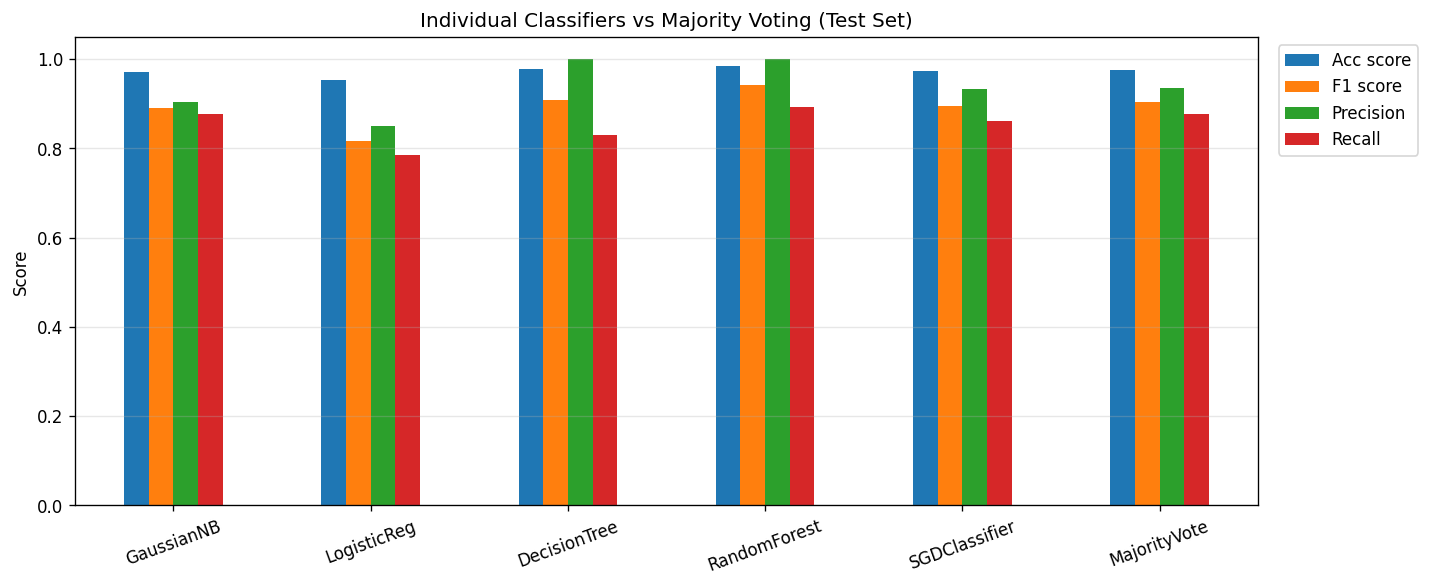

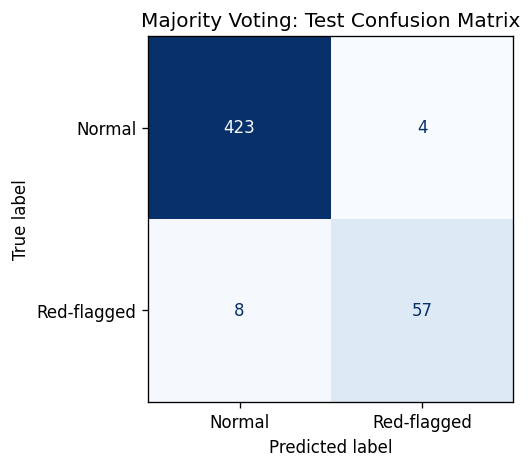

In [12]:
ax = summary.plot(kind='bar', x='Learner', y=METRICS, figsize=(12, 5), rot=20)
ax.set_title('Individual Classifiers vs Majority Voting (Test Set)')
ax.set_ylabel('Score')
ax.set_xlabel('')
ax.set_ylim(0, 1.05)
ax.grid(axis='y', alpha=0.3)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'model_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_vote, labels=[0, 1],
    display_labels=['Normal', 'Red-flagged'], cmap='Blues', colorbar=False, ax=ax)
ax.set_title('Majority Voting: Test Confusion Matrix')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'ensemble_confusion_matrix.png', dpi=180)
plt.show()


## 11. Interpretation and limitations
- Compare recall and precision as well as accuracy; the positive class is a minority.
- Majority voting can lose useful minority opinions. Similar model errors limit its benefit.
- The feature set and model settings come from a teaching example; no claim of optimality.
- A payment status must be available at prediction time to be a valid input in a real system.
- A random holdout does not address temporal drift or repeated-customer leakage.
- No oversampling, SMOTE, cost-sensitive optimization or threshold tuning is performed.
- Missing-ID deletion and fixed status imputation can introduce bias.
- These results concern a course red-flag label, not verified real-world fraud outcomes.

**Attribution:** based on HKU COMP7409A Tutorial 1, *Fraud Detection via classical ML*,
TA Link Chen; the slides credit Dr. H. F. Ting. The equal-weight voting extension,
reproducible pipelines, expanded validation and visual comparisons were developed
with AI assistance. Course slides and raw data are not redistributed in this package.
